# Проверка гипотез в Python и результаты A/B-теста

**Автор проекта: Наместникова Соня**

В проекте две части. Сначала я проверю гипотезу о времени чтения и прослушивания книг в Москве и Санкт-Петербурге. Затем проверю корректность A/B-теста интернет-магазина и сравню конверсию в покупку между группами.

## Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats as st
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

pd.set_option('display.float_format', '{:.4f}'.format)

# Часть 1. Проверка гипотезы по данным Яндекс Книг

## 1.1. Загрузка и знакомство с данными

In [2]:
books = pd.read_csv(
    'https://code.s3.yandex.net/datasets/yandex_knigi_data.csv'
)

# В файле сохранился технический столбец (с индексом), для анализа он не нужен
books = books.drop(columns=['Unnamed: 0'], errors='ignore')

display(books.head())
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


,city,puid,hours
0,Москва,9668,26.1678
1,Москва,16598,82.1112
2,Москва,80401,4.6569
3,Москва,140205,1.8406
4,Москва,248755,151.3264


In [3]:
print('Размер таблицы:', books.shape)
print('Количество пропусков:')
display(books.isna().sum())
print('Количество явных дубликатов:', books.duplicated().sum())
print('Количество уникальных пользователей:', books['puid'].nunique())

Размер таблицы: (8784, 3)
Количество пропусков:
Количество явных дубликатов: 0
Количество уникальных пользователей: 8540


city     0
puid     0
hours    0
dtype: int64

В таблице 8 784 строки. Пропусков и полных дубликатов нет. Типы данных соответствуют содержанию столбцов. Теперь отдельно проверю повторы в идентификаторах пользователей.

## 1.2. Проверка повторяющихся идентификаторов

In [4]:
duplicate_users = books[books.duplicated('puid', keep=False)].sort_values('puid')

print('Повторяющихся идентификаторов:', duplicate_users['puid'].nunique())
print(
    'Дубликатов внутри одной пары город-пользователь:',
    books.duplicated(['city', 'puid']).sum()
)
display(duplicate_users.head(10))

Повторяющихся идентификаторов: 244
Дубликатов внутри одной пары город-пользователь: 0


,city,puid,hours
35,Москва,2637041,10.3174
6247,Санкт-Петербург,2637041,3.8839
6274,Санкт-Петербург,9979490,1.3030
134,Москва,9979490,32.4156
145,Москва,10597984,42.9315
6279,Санкт-Петербург,10597984,9.0413
6283,Санкт-Петербург,10815097,0.3233
150,Москва,10815097,9.0867
187,Москва,13626259,21.1042
6300,Санкт-Петербург,13626259,1.6484


In [5]:
cities_per_user = books.groupby('puid')['city'].nunique()
ambiguous_user_ids = cities_per_user[cities_per_user > 1].index

print('Пользователей, указанных сразу в двух городах:', len(ambiguous_user_ids))

books_clean = books[~books['puid'].isin(ambiguous_user_ids)].copy()
print('Строк после удаления таких пользователей:', len(books_clean))

Пользователей, указанных сразу в двух городах: 244
Строк после удаления таких пользователей: 8296


Нашлось 244 пользователя, которые указаны одновременно в Москве и Санкт-Петербурге. Если оставить их в обеих выборках, группы перестанут быть независимыми. Поэтому я убрала этих пользователей из обеих групп. После очистки осталось 8 296 наблюдений.

## 1.3. Сравнение групп

In [6]:
city_stats = (
    books_clean.groupby('city')
    .agg(
        users=('puid', 'nunique'),
        mean_hours=('hours', 'mean'),
        median_hours=('hours', 'median'),
        std_hours=('hours', 'std'),
        min_hours=('hours', 'min'),
        max_hours=('hours', 'max')
    )
)

display(city_stats)

,users,mean_hours,median_hours,std_hours,min_hours,max_hours
city,,,,,,
Москва,5990,10.8482,0.8882,36.9256,0.0000,857.2094
Санкт-Петербург,2306,11.2644,0.8754,39.8318,0.0000,978.7648


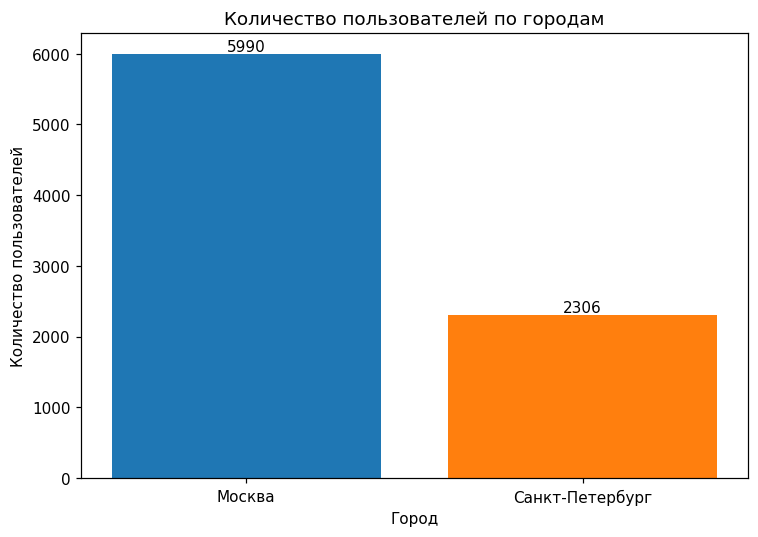

In [7]:
plt.figure(figsize=(7, 5))
bars = plt.bar(city_stats.index, city_stats['users'], color=['C0', 'C1'])
plt.title('Количество пользователей по городам')
plt.xlabel('Город')
plt.ylabel('Количество пользователей')
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.0f}',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

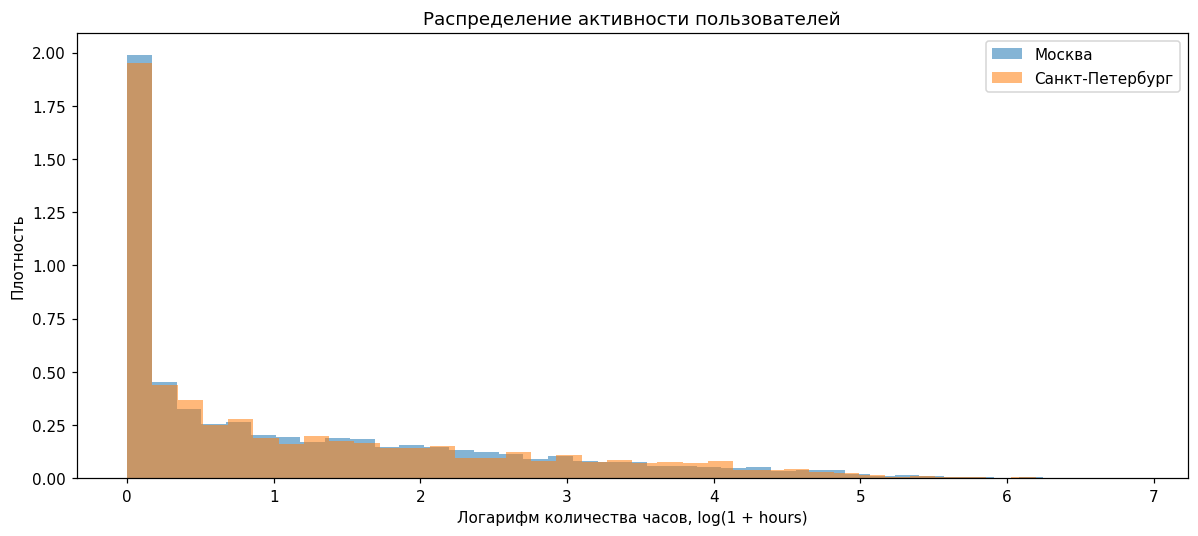

In [8]:
plt.figure(figsize=(11, 5))

for city in ['Москва', 'Санкт-Петербург']:
    values = np.log1p(books_clean.loc[books_clean['city'] == city, 'hours'])
    plt.hist(values, bins=40, alpha=0.55, density=True, label=city)

plt.title('Распределение активности пользователей')
plt.xlabel('Логарифм количества часов, log(1 + hours)')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

После очистки в московской группе 5 990 пользователей, в петербургской 2 306. Среднее время активности составляет 10,85 и 11,26 часа соответственно. При этом медианы меньше одного часа, а максимальные значения превышают 800 часов. Распределения сильно скошены вправо, но выборки достаточно большие. Для сравнения средних использую t-тест Уэлча: он не требует равенства дисперсий и подходит при разных размерах групп.

## 1.4. Проверка гипотезы

Проверяю односторонние гипотезы:

* **H0:** среднее время активности пользователей Санкт-Петербурга не больше среднего времени пользователей Москвы, $\mu_{СПб} \leq \mu_{Москва}$.
* **H1:** среднее время активности пользователей Санкт-Петербурга больше среднего времени пользователей Москвы, $\mu_{СПб} > \mu_{Москва}$.

Уровень статистической значимости: 0,05.

In [9]:
moscow_hours = books_clean.loc[books_clean['city'] == 'Москва', 'hours']
spb_hours = books_clean.loc[books_clean['city'] == 'Санкт-Петербург', 'hours']

alpha = 0.05

books_test = st.ttest_ind(
    spb_hours,
    moscow_hours,
    equal_var=False,
    alternative='greater'
)

print(f'Среднее в Москве: {moscow_hours.mean():.2f} часа')
print(f'Среднее в Санкт-Петербурге: {spb_hours.mean():.2f} часа')
print(f'Разница средних: {spb_hours.mean() - moscow_hours.mean():.2f} часа')
print(f't-статистика: {books_test.statistic:.4f}')
print(f'p-value: {books_test.pvalue:.6f}')

if books_test.pvalue < alpha:
    print('Отвергаю H0: среднее время в Санкт-Петербурге статистически значимо больше.')
else:
    print('Не отвергаю H0: статистически значимое превосходство Санкт-Петербурга не подтверждено.')

Среднее в Москве: 10.85 часа
Среднее в Санкт-Петербурге: 11.26 часа
Разница средних: 0.42 часа
t-статистика: 0.4350
p-value: 0.331796
Не отвергаю H0: статистически значимое превосходство Санкт-Петербурга не подтверждено.


## 1.5. Аналитическая записка

Для проверки я использовала односторонний t-тест Уэлча для двух независимых выборок. Уровень значимости равен 0,05. Этот вариант t-теста выбран из-за разного размера групп и высокой вариативности значений.

Среднее время активности составило 10,85 часа в Москве и 11,26 часа в Санкт-Петербурге. Разница равна 0,42 часа в пользу Санкт-Петербурга. Полученное p-value равно 0,331796. Оно больше 0,05, поэтому нулевую гипотезу отвергнуть нельзя. По имеющимся данным нельзя утверждать, что пользователи из Санкт-Петербурга в среднем проводят в сервисе больше времени.

Одна из возможных причин такого результата состоит в том, что поведение пользователей двух городов действительно похоже. Также в данных очень большой разброс: медиана не достигает одного часа, но встречаются значения свыше 800 часов. На фоне такой вариативности небольшая разница средних могла оказаться случайной.

# Часть 2. Анализ результатов A/B-теста

## 2.1. Загрузка данных

In [10]:
participants = pd.read_csv(
    'https://code.s3.yandex.net/datasets/ab_test_participants.csv'
)
events = pd.read_csv(
    'https://code.s3.yandex.net/datasets/ab_test_events.zip',
    low_memory=False
)

events['event_dt'] = pd.to_datetime(events['event_dt'])

display(participants.head())
display(events.head())

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [11]:
print('Таблица участников:', participants.shape)
participants.info()

print('\nТаблица событий:', events.shape)
events.info()

Таблица участников: (14525, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB

Таблица событий: (787286, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


## 2.2. Проверка качества данных

In [12]:
print('Пропуски в таблице участников:')
display(participants.isna().sum())
print('Явные дубликаты участников:', participants.duplicated().sum())

print('\nПропуски в таблице событий:')
display(events.isna().sum())
print('Явные дубликаты событий:', events.duplicated().sum())
print('Служебные события GLOBAL:', events['user_id'].eq('GLOBAL').sum())

Пропуски в таблице участников:
Явные дубликаты участников: 0

Пропуски в таблице событий:
Явные дубликаты событий: 36318
Служебные события GLOBAL: 58495


user_id    0
group      0
ab_test    0
device     0
dtype: int64

user_id            0
event_dt           0
event_name         0
details       538264
dtype: int64

In [13]:
events_clean = events.drop_duplicates().copy()

print('Удалено явных дубликатов событий:', len(events) - len(events_clean))
print(
    'Период данных:',
    events_clean['event_dt'].min(),
    '-',
    events_clean['event_dt'].max()
)
display(events_clean['event_name'].value_counts())

Удалено явных дубликатов событий: 36318
Период данных: 2020-12-01 00:00:00 - 2020-12-31 23:59:48


event_name
login                                 228196
product_page                          187479
registration                          144183
purchase                              100719
product_cart                           90388
End of Black Friday Ads Campaign           1
Start of Christmas&New Year Promo          1
Start of CIS New Year Gift Lottery         1
Name: count, dtype: int64

В таблице участников пропусков и дубликатов нет. В событиях найдено 36 318 полных дубликатов, их я удалила. Пропуски есть только в `details`: это дополнительное поле, которое заполняется не для каждого типа события, поэтому такие строки удалять не нужно. Три служебных события с `user_id = GLOBAL` не относятся к конкретным пользователям и при объединении в тест не попадут.

## 2.3. Проверка участников теста

In [14]:
target_test = participants.query("ab_test == 'interface_eu_test'").copy()

print('Участников целевого теста:', target_test['user_id'].nunique())
display(target_test.groupby('group')['user_id'].nunique())

group_intersection = (
    target_test.groupby('user_id')['group'].nunique().gt(1).sum()
)
print('Пользователей, попавших в обе группы:', group_intersection)

Участников целевого теста: 10850
Пользователей, попавших в обе группы: 0


group
A    5383
B    5467
Name: user_id, dtype: int64

In [15]:
other_test_users = set(
    participants.loc[
        participants['ab_test'] != 'interface_eu_test',
        'user_id'
    ]
)

parallel_test_users = set(target_test['user_id']).intersection(other_test_users)

print('Участников одновременно в двух тестах:', len(parallel_test_users))
display(
    target_test[target_test['user_id'].isin(parallel_test_users)]
    ['group'].value_counts()
)

Участников одновременно в двух тестах: 887


group
B    456
A    431
Name: count, dtype: int64

Разница в размере групп: 1.19%


group
A    4952
B    5011
Name: user_id, dtype: int64

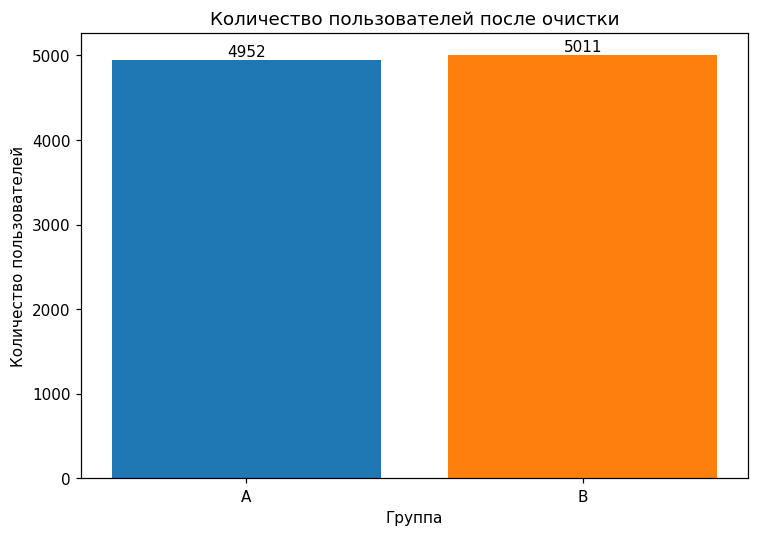

In [16]:
test_users = target_test[
    ~target_test['user_id'].isin(parallel_test_users)
].copy()

users_by_group = test_users.groupby('group')['user_id'].nunique()
group_difference = 100 * abs(users_by_group['A'] - users_by_group['B']) / users_by_group['A']

display(users_by_group)
print(f'Разница в размере групп: {group_difference:.2f}%')

plt.figure(figsize=(7, 5))
bars = plt.bar(users_by_group.index, users_by_group.values, color=['C0', 'C1'])
plt.title('Количество пользователей после очистки')
plt.xlabel('Группа')
plt.ylabel('Количество пользователей')
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.0f}',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

device,Android,Mac,PC,iPhone
group,,,,
A,45.7200,10.4000,24.7000,19.1800
B,44.2600,10.2000,25.9800,19.5600


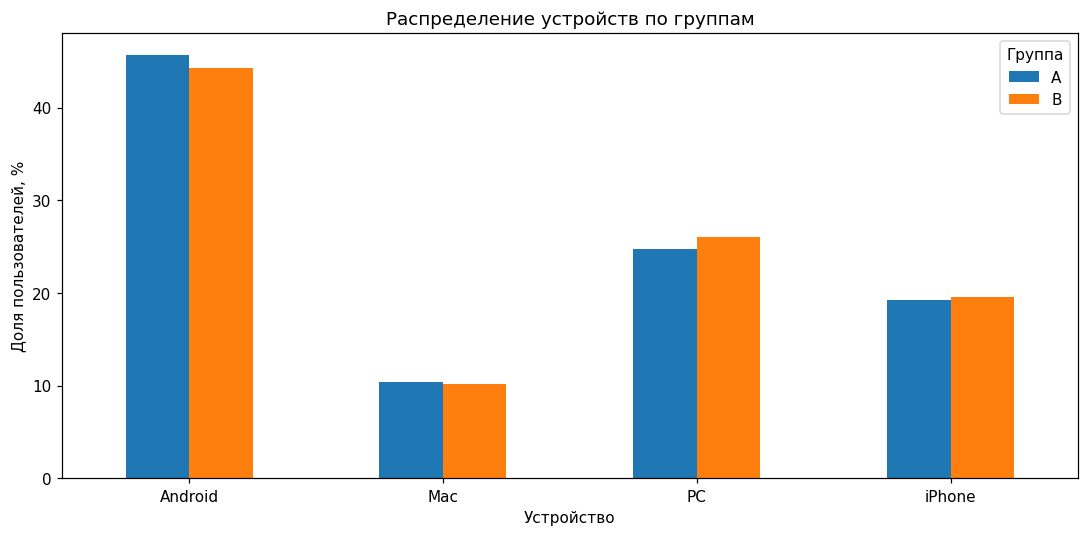

In [17]:
device_share = pd.crosstab(
    test_users['group'],
    test_users['device'],
    normalize='index'
) * 100

display(device_share.round(2))

device_share.T.plot(kind='bar', figsize=(10, 5))
plt.title('Распределение устройств по группам')
plt.xlabel('Устройство')
plt.ylabel('Доля пользователей, %')
plt.xticks(rotation=0)
plt.legend(title='Группа')
plt.tight_layout()
plt.show()

Внутри `interface_eu_test` пересечений между группами нет. Однако 887 пользователей участвовали ещё и в параллельном тесте. Другой эксперимент мог повлиять на их поведение, поэтому я исключила таких пользователей.

После очистки осталось 4 952 пользователя в группе A и 5 011 в группе B. Разница в размере групп равна 1,19%. Распределение по устройствам тоже близкое: максимальная разница между группами составляет меньше 1,5 процентного пункта. По этим признакам группы сопоставимы.

## 2.4. Проверка периода наблюдения

In [18]:
test_events = events_clean.merge(
    test_users[['user_id', 'group']],
    on='user_id',
    how='inner'
)

registrations = (
    test_events[test_events['event_name'] == 'registration']
    .groupby('user_id', as_index=False)
    .agg(registration_dt=('event_dt', 'min'))
)

test_users = test_users.merge(registrations, on='user_id', how='left')

print('Пользователей без события регистрации:', test_users['registration_dt'].isna().sum())
print(
    'Период регистрации участников:',
    test_users['registration_dt'].min(),
    '-',
    test_users['registration_dt'].max()
)

Пользователей без события регистрации: 0
Период регистрации участников: 2020-12-06 14:10:01 - 2020-12-24 21:57:10


In [19]:
observation_end = events_clean['event_dt'].max()
test_users['full_7_days'] = (
    test_users['registration_dt'] + pd.Timedelta(days=7) <= observation_end
)

display(test_users['full_7_days'].value_counts())
print('Конец доступных данных:', observation_end)

Конец доступных данных: 2020-12-31 23:59:48


full_7_days
True    9963
Name: count, dtype: int64

У всех участников есть событие регистрации. Пользователи регистрировались с 6 по 24 декабря, а события доступны до конца 31 декабря. Для каждого участника есть полное семидневное окно наблюдения, поэтому дополнительно сокращать выборку не нужно.

## 2.5. Оценка достаточности выборки

По техническому заданию базовая конверсия равна 30%, а минимальный ожидаемый рост составляет 3 процентных пункта, то есть целевая конверсия равна 33%. Доверительная вероятность составляет 95%, поэтому уровень значимости равен 5%. Целевая мощность теста равна 80%. Для оценки использую двусторонний вариант расчёта. Он требует немного большую выборку и поэтому даёт более осторожную оценку.


In [20]:
baseline_conversion = 0.30
mde = 0.03
expected_conversion = baseline_conversion + mde
confidence_level = 0.95
alpha_ab = 1 - confidence_level
target_power = 0.80

effect_size = abs(
    proportion_effectsize(baseline_conversion, expected_conversion)
)

power_analysis = NormalIndPower()
required_sample = power_analysis.solve_power(
    effect_size=effect_size,
    power=target_power,
    alpha=alpha_ab,
    ratio=1,
    alternative='two-sided'
)
required_sample_per_group = int(np.ceil(required_sample))

actual_a = int(users_by_group['A'])
actual_b = int(users_by_group['B'])
actual_min_group = min(actual_a, actual_b)
actual_power = power_analysis.power(
    effect_size=effect_size,
    nobs1=actual_a,
    alpha=alpha_ab,
    ratio=actual_b / actual_a,
    alternative='two-sided'
)

print(f'Доверительная вероятность: {confidence_level:.0%}')
print(f'Уровень значимости alpha: {alpha_ab:.0%}')
print(f'Целевая мощность: {target_power:.0%}')
print(f'Необходимый размер каждой группы: {required_sample_per_group}')
print(f'Фактический размер групп: A = {actual_a}, B = {actual_b}')
print(f'Фактическая мощность: {actual_power:.2%}')

if (actual_min_group >= required_sample_per_group) and (actual_power >= target_power):
    print('Фактической выборки достаточно для обнаружения эффекта в 3 п.п.')
else:
    print('Фактической выборки недостаточно для обнаружения эффекта в 3 п.п.')


Доверительная вероятность: 95%
Уровень значимости alpha: 5%
Целевая мощность: 80%
Необходимый размер каждой группы: 3762
Фактический размер групп: A = 4952, B = 5011
Фактическая мощность: 89.69%
Фактической выборки достаточно для обнаружения эффекта в 3 п.п.


**Вывод:** при доверительной вероятности 95%, уровне значимости 5% и мощности 80% для обнаружения роста конверсии с 30% до 33% требуется не менее 3 762 пользователей в каждой группе. После очистки осталось 4 952 пользователя в группе A и 5 011 в группе B. Фактическая мощность составляет около 89,7%, поэтому выборки достаточно.


## 2.6. Расчёт конверсии за семь дней

In [21]:
events_with_registration = test_events.merge(
    test_users[['user_id', 'registration_dt']],
    on='user_id',
    how='inner'
)

events_7d = events_with_registration[
    (events_with_registration['event_dt'] >= events_with_registration['registration_dt'])
    &
    (events_with_registration['event_dt'] < events_with_registration['registration_dt'] + pd.Timedelta(days=7))
].copy()

purchase_users = set(
    events_7d.loc[events_7d['event_name'] == 'purchase', 'user_id']
)

test_users['purchase_7d'] = test_users['user_id'].isin(purchase_users)

conversion_metrics = (
    test_users.groupby('group')
    .agg(
        users=('user_id', 'nunique'),
        buyers=('purchase_7d', 'sum'),
        conversion=('purchase_7d', 'mean')
    )
)

display(conversion_metrics)

,users,buyers,conversion
group,,,
A,4952,1377,0.2781
B,5011,1480,0.2954


Конверсия группы A: 27.81%
Конверсия группы B: 29.54%
Абсолютная разница B - A: 1.73%


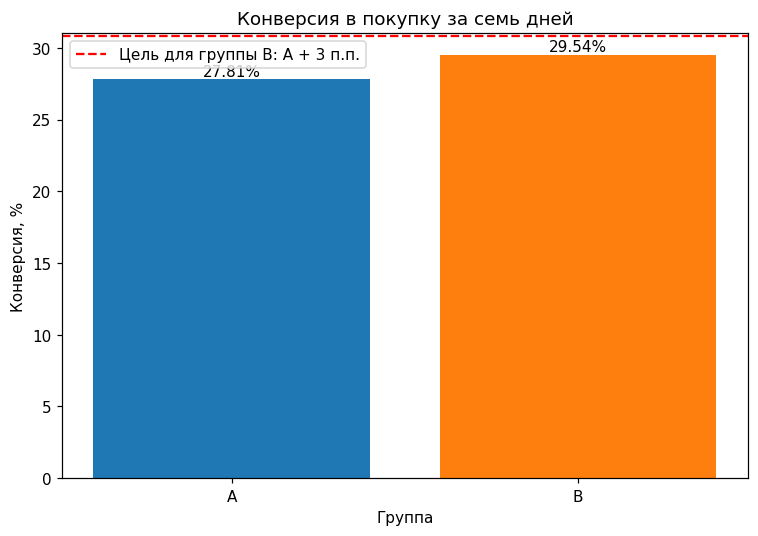

In [22]:
conversion_a = conversion_metrics.loc['A', 'conversion']
conversion_b = conversion_metrics.loc['B', 'conversion']
observed_difference = conversion_b - conversion_a
target_difference = 0.03

plt.figure(figsize=(7, 5))
bars = plt.bar(
    conversion_metrics.index,
    conversion_metrics['conversion'] * 100,
    color=['C0', 'C1']
)
plt.axhline(
    (conversion_a + target_difference) * 100,
    color='red',
    linestyle='--',
    label='Цель для группы B: A + 3 п.п.'
)
plt.title('Конверсия в покупку за семь дней')
plt.xlabel('Группа')
plt.ylabel('Конверсия, %')
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f}%',
        ha='center',
        va='bottom'
    )
plt.legend()
plt.tight_layout()
plt.show()

print(f'Конверсия группы A: {conversion_a:.2%}')
print(f'Конверсия группы B: {conversion_b:.2%}')
print(f'Абсолютная разница B - A: {observed_difference:.2%}')

Конверсия составила 27,81% в группе A и 29,54% в группе B. Разница равна 1,73 процентного пункта. Группа B показывает лучший результат, но наблюдаемый рост меньше целевых 3 процентных пунктов.

## 2.7. Статистическая проверка

Сначала проверю, есть ли положительный эффект вообще:

* **H0:** конверсия группы B не выше конверсии группы A, $p_B \leq p_A$.
* **H1:** конверсия группы B выше конверсии группы A, $p_B > p_A$.

Использую односторонний z-тест пропорций с уровнем значимости 0,05.

In [23]:
buyers = [
    conversion_metrics.loc['B', 'buyers'],
    conversion_metrics.loc['A', 'buyers']
]
users = [
    conversion_metrics.loc['B', 'users'],
    conversion_metrics.loc['A', 'users']
]

z_stat, p_value = proportions_ztest(
    buyers,
    users,
    alternative='larger'
)

print(f'z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

if p_value < alpha:
    print('Отвергаю H0: в группе B конверсия статистически значимо выше.')
else:
    print('Не отвергаю H0: статистически значимое улучшение не подтверждено.')

z-статистика: 1.9070
p-value: 0.028263
Отвергаю H0: в группе B конверсия статистически значимо выше.


Односторонний тест дал p-value 0,028263. Оно меньше 0,05, поэтому рост конверсии в группе B статистически значим. Но техническое задание требует не просто роста, а увеличения как минимум на 3 процентных пункта. Проверю отдельно, можно ли подтвердить превышение этого порога.

In [24]:
standard_error = np.sqrt(
    conversion_a * (1 - conversion_a) / conversion_metrics.loc['A', 'users']
    + conversion_b * (1 - conversion_b) / conversion_metrics.loc['B', 'users']
)

z_target = (observed_difference - target_difference) / standard_error
p_value_target = st.norm.sf(z_target)

print(f'Наблюдаемый рост: {observed_difference:.2%}')
print(f'Целевой рост: {target_difference:.2%}')
print(f'p-value для проверки роста более 3 п.п.: {p_value_target:.6f}')

Наблюдаемый рост: 1.73%
Целевой рост: 3.00%
p-value для проверки роста более 3 п.п.: 0.919840


p-value для проверки превышения порога 3 процентных пункта равно 0,919840. Данных недостаточно, чтобы подтвердить рост на 3 процентных пункта или больше.

## 2.8. Итоговый вывод по A/B-тесту

В целевом тесте не было пересечений между группами, но 887 пользователей одновременно участвовали в другом эксперименте. Я исключила их, чтобы не смешивать влияние двух изменений. После очистки в группе A осталось 4 952 пользователя, в группе B 5 011. Группы близки по размеру и распределению устройств. У всех пользователей есть полное семидневное окно наблюдения.

При доверительной вероятности 95% и целевой мощности 80% для обнаружения роста конверсии с 30% до 33% требовалось не менее 3 762 пользователей в каждой группе. Фактическая мощность составила около 89,7%, поэтому выборки достаточно.

Конверсия в покупку составила 27,81% в группе A и 29,54% в группе B. Новый интерфейс повысил конверсию на 1,73 процентного пункта. Односторонний z-тест показал статистически значимый рост: p-value равно 0,028263.

Несмотря на это, заявленная в техническом задании цель не достигнута. Фактический рост меньше 3 процентных пунктов, а отдельная проверка этого порога дала p-value 0,919840. Значит, нельзя утверждать, что новый интерфейс увеличивает конверсию как минимум на 3 процентных пункта.

Я бы не принимала решение о полном запуске только по результатам этого теста. Новый вариант выглядит перспективно, но его стоит доработать или проверить повторно без параллельного эксперимента. При следующем тесте важно заранее исключить пересечение участников между экспериментами.

# Общий вывод

В первой части проекта гипотеза о более высокой средней активности пользователей Санкт-Петербурга не подтвердилась: p-value равно 0,331796.

Во второй части при уровне значимости 5% фактическая мощность теста составила около 89,7%, поэтому размер выборки оказался достаточным для обнаружения роста на 3 процентных пункта. Новый интерфейс дал статистически значимый положительный эффект, но прирост составил только 1,73 процентного пункта вместо требуемых 3. Поэтому продуктовую гипотезу в исходной формулировке подтвердить нельзя.